# WSA/HUX speed from the PFSS rings, auto-calibrated (not built)

**The question:** does a calibrated Wang-Sheeley-Arge (WSA) speed, carried to Earth by HUX,
improve the submitted linear model (which since 2026-11-07 includes the PFSS current-sheet
distance)? And how good is WSA alone?

- **Model:** `models.wsa`: v = v0 + dv/(1+fs)^α · (1 − 0.8 exp(−(θb/w)^δ))³ per ring longitude, HUX from 21.5 R☉ to 1 AU, read at the longitude facing Earth (+ shift).
- **Offline calibration:** per fold, the six parameters by Nelder-Mead on the official S_final of WSA alone, on 1,500 fit runs.
- **Rolling calibration:** per run, an offset and scale ridge-fitted to the same map's hindcast of the last 14 or 27 days.
- **Rule, set before running:** keep a linear-model variant only if > 1% better than the submitted config and winning ≥ 4 of 6 folds.

Study: `python -m training.wsa_model`; results `src/experiments/wsa_model.csv`; write-up `docs/wsa.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import wsa_model as wm

d = pd.read_csv(wm.EXPERIMENTS / "wsa_model.csv").set_index("fold")
linear = [c for c in d.columns if c.startswith("linear +")]
alone = [c for c in d.columns if c.startswith("alone")]
rel = d[linear].div(d["linear shipped"], axis=0)
summary = pd.DataFrame({
    "vs shipped %": 100 * (np.exp(np.log(rel).mean()) - 1),
    "folds won": (rel < 1).sum(),
}).sort_values("vs shipped %")
summary["keep"] = ((summary["vs shipped %"] < -100 * wm.KEEP_GAIN)
                   & (summary["folds won"] >= wm.KEEP_FOLDS))
summary.round(3)

,vs shipped %,folds won,keep
linear + wsa_speed_lead_0h,-0.748,4,False
linear + wsa_speed_lead_12h,-0.513,4,False
linear + wsa_speed_lead_24h,-0.257,4,False
linear + wsa_speed_lead_0h rolling 14d,-0.116,4,False
linear + wsa_speed_lead_12h rolling 14d,-0.046,4,False
linear + wsa_speed_lead_24h rolling 14d,0.025,3,False
linear + wsa_speed_lead_0h rolling 27d,0.098,3,False
linear + wsa_speed_lead_12h rolling 27d,0.106,3,False
linear + wsa_speed_lead_24h rolling 27d,0.115,3,False


## 1. WSA added to the linear model, by fold

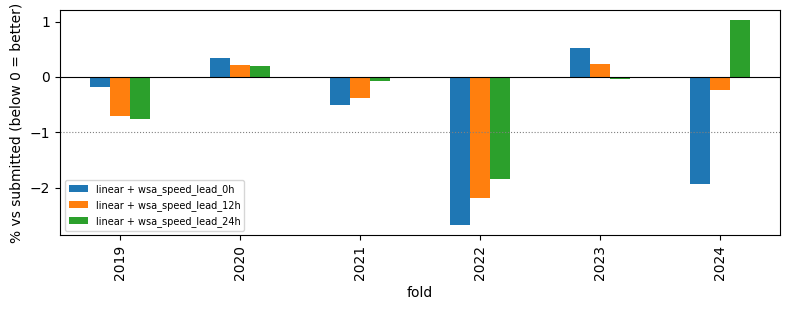

In [2]:
best = summary.index[:3]
ax = (100 * (rel[best] - 1)).plot.bar(figsize=(8, 3.2))
ax.axhline(0, color="k", lw=.8)
ax.axhline(-100 * wm.KEEP_GAIN, color="grey", ls=":", lw=.8)
ax.set_ylabel("% vs submitted (below 0 = better)")
ax.legend(fontsize=7)
plt.tight_layout()

The best variant (offline WSA speed for the hour being forecast) gains 0.75% and wins 4 folds,
driven by the 2022 and 2024 folds (−2.7%, −1.9%). It falls short of the 1% bar. The rolling
re-fit makes the feature worse, not better.

## 2. WSA alone against persistence

,alone offline,alone rolling 14d,alone rolling 27d,linear shipped
fold,,,,
2019,1.120,1.127,1.028,0.720
2020,0.990,1.092,1.023,0.691
2021,1.095,1.181,1.135,0.809
2022,1.117,1.247,1.241,0.852
2023,1.146,1.187,1.209,0.833
2024,0.993,1.044,0.991,0.785


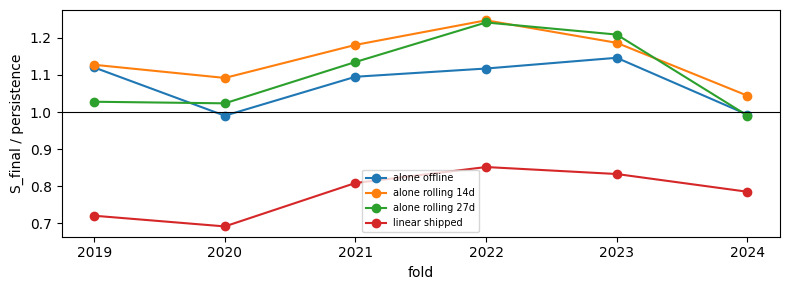

In [3]:
ratio = d[alone + ["linear shipped"]].div(d["persistence"], axis=0)
ax = ratio.plot(marker="o", figsize=(8, 3))
ax.axhline(1, color="k", lw=.8)
ax.set_ylabel("S_final / persistence")
ax.legend(fontsize=7)
plt.tight_layout()
ratio.round(3)

Calibrated WSA alone is 7.5% worse than persistence on average and beats it in no fold by
more than 1%. The calibration cuts its error from about 180 to about 107 km/s on the fit runs,
but the 72-hour horizon favours persistence, and the linear model is at 0.78.

## 3. The calibrated parameters

In [4]:
params = d[[c for c in d.columns if c.startswith("param ")]]
params.columns = [c.split()[1] for c in params.columns]
bounds = pd.DataFrame(wm.BOUNDS, index=["low", "high"])
pd.concat([params.round(3), bounds])

,v0,dv,alpha,w,delta,shift
2019,337.131,900.000,0.333,0.353,0.471,1.651
2020,329.573,793.313,0.328,0.526,0.993,7.510
2021,341.507,854.900,0.361,0.468,0.832,1.775
2022,352.976,721.693,0.367,0.457,1.350,1.672
2023,364.072,717.380,0.344,0.540,0.877,2.647
2024,374.956,631.685,0.328,0.757,3.814,1.847
low,150.000,100.000,0.020,0.200,0.300,-60.000
high,450.000,900.000,1.500,15.000,4.000,60.000


- **dv** reaches its 900 km/s cap in the 2019 fold and is 630–850 elsewhere; **v0** rises steadily from 337 to 375 km/s as more solar-maximum years enter the fit.
- **w** (0.35–0.76°) is far below the literature 2–4°: on these maps the boundary distance barely matters, which matches the PFSS study, where `theta_b` added nothing.
- **α** is a stable 0.33–0.37, near the literature 2/9–1/3.

## 4. The calibration objective

S_final on the fit runs, from the literature defaults to the calibrated values.

In [5]:
d[["s_default", "s_calibration"]].round(1)

,s_default,s_calibration
fold,,
2019,185.8,110.9
2020,175.5,106.2
2021,172.3,101.7
2022,180.4,107.1
2023,180.1,107.0
2024,182.7,108.6
